In [35]:
import os
import sys 
print("Active Environment Path:", sys.executable)
from pathlib import Path
import json
import subprocess
import importlib
import tempfile

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, PrecisionRecallDisplay
import shapely
from azure.identity import DefaultAzureCredential
from azure.ai.ml import MLClient
from joblib import Parallel, delayed

import pystac_client
import planetary_computer
import odc.stac
import rasterio.features
from affine import Affine
import time

from functools import reduce
# local
os.chdir("/home/azureuser/EBRD_Tillage/AK_Experiments/AK_pipeline")
sys.path.append(os.getcwd())
from Generic.addSentinelIndices import calculateSentinelIndex, SENTINEL_INDEX_DEPENDENCIES
from utils.classify_tillage import classify_tillage
from ml.nominal_classification import RFC 
from ml.ordinal_regression import RFR

Active Environment Path: /anaconda/envs/geospatial-base/bin/python


In [36]:

def log(message):
    current_time = time.strftime("%H:%M:%S")
    print(f"[{current_time}] {message}")

In [37]:

RUN_ACQUIRE_PATH = Path("/home/azureuser/EBRD_Tillage/EBRD_tillage_monitoring-main/src/acquire/run_acquire.py")  
TEMP_DIR = Path("/home/azureuser/EBRD_Tillage/data/temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DATA_PATH= Path("/home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp")  

# Global Variables 
local_path_append = 'Version4'
MLDFS_DIR = Path("/home/azureuser/EBRD_Tillage/data/output/mldfs")
MLDFS_DIR_S2 = MLDFS_DIR / ('s2'+'_'+local_path_append )
MLDFS_DIR_S1 = MLDFS_DIR / ('s1'+'_'+local_path_append )


MLDFS_DIR_LIST = [MLDFS_DIR_S2, MLDFS_DIR_S1]

In [43]:
# ==============================================================================
# 1. SETUP & PATH CONFIGURATION
# ==============================================================================
print(f"Reading shapefile from: {INPUT_DATA_PATH}")
gdf = gpd.read_file(INPUT_DATA_PATH).drop(columns = ['index'])
gdf=gdf.to_crs("EPSG:4326")
# Quick check
print(f"Successfully loaded {len(gdf)} rows.")
gdf = gdf.rename(columns={'Beginning':'start_date',"End date":'end_date'})
print(gdf.columns)
gdf["start_date"] = pd.to_datetime(gdf["start_date"])
gdf["end_date"] = pd.to_datetime(gdf["end_date"])

print('++++++++++++++++++++++++++++++++++++++++++')
ml_df_list = []
for ml_path in MLDFS_DIR_LIST: 
    ml_df_list.append(pd.concat([pd.read_csv(f) for f in ml_path.glob("*.csv")], ignore_index=True))


id_col = 'fid'
id_sets = [set(df[id_col]) for df in ml_df_list]
all_ids_match = all(s == id_sets[0] for s in id_sets[1:])
all_unique_ids = set.union(*id_sets)
common_ids = set.intersection(*id_sets)
missing_ids = all_unique_ids - common_ids
print(len(missing_ids))

# Merge all DataFrames sequentially using outer join
mldf = reduce(lambda left, right: pd.merge(left, right, on=[id_col,'Operation','operation_'], how='outer'), ml_df_list)
mldf

Reading shapefile from: /home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp
Successfully loaded 5746 rows.
Index(['fid', 'Operation', 'Group of o', 'Machinery', 'Machine', 'start_date',
       'end_date', 'Field ID', 'Crop', 'Year', 'Area, ha', 'operation_',
       'source_fil', 'FieldAreaH', 'Completion', 'Classifica', 'geometry'],
      dtype='str')
++++++++++++++++++++++++++++++++++++++++++
989


,fid,operation_,Operation,NDVI__min__mean,NDVI__mean__mean,NDVI__median__mean,NDVI__max__mean,NDTI__min__mean,NDTI__mean__mean,NDTI__median__mean,...,vh__median__mean,vh__max__mean,vv__min__mean,vv__mean__mean,vv__median__mean,vv__max__mean,vvvh__min__mean,vvvh__mean__mean,vvvh__median__mean,vvvh__max__mean
0,1.0,Tillage,Disking to a depth of 5-8 см.,0.235041,0.235041,0.235041,0.235041,0.085000,0.085000,0.085000,...,0.007459,0.012880,0.032331,0.054013,0.051467,0.080785,4.025027,8.585940,7.734785,14.849167
1,3.0,Tillage,Disking to a depth of 5-8 см.,0.064090,0.064090,0.064090,0.064090,0.050497,0.050497,0.050497,...,0.007679,0.013142,0.034599,0.057310,0.054709,0.085221,4.176753,8.874758,8.034563,15.253151
2,4.0,Tillage,Disking to a depth of 5-8 см.,0.064090,0.064090,0.064090,0.064090,0.050497,0.050497,0.050497,...,0.007679,0.013142,0.034599,0.057310,0.054709,0.085221,4.176753,8.874758,8.034563,15.253151
3,5.0,Tillage,Disking to a depth of 5-8 см.,0.063994,0.149566,0.149566,0.235137,0.047652,0.067748,0.067748,...,0.007679,0.013142,0.034599,0.057310,0.054709,0.085221,4.176753,8.874758,8.034563,15.253151
4,6.0,Tillage,Disking to a depth of 5-8 см.,0.063994,0.149566,0.149566,0.235137,0.047652,0.067748,0.067748,...,0.007679,0.013142,0.034599,0.057310,0.054709,0.085221,4.176753,8.874758,8.034563,15.253151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5739,16687.0,Tillage,Disking to a depth of 5-8 см.,0.138862,0.153821,0.148984,0.173617,-0.012370,-0.002904,-0.004294,...,0.008949,0.011487,0.050039,0.072783,0.072783,0.095528,6.573099,9.473404,9.473404,12.373708
5740,16688.0,Tillage,Disking to a depth of 5-8 см.,0.138862,0.153821,0.148984,0.173617,-0.012370,-0.002904,-0.004294,...,0.008949,0.011487,0.050039,0.072783,0.072783,0.095528,6.573099,9.473404,9.473404,12.373708
5741,16689.0,Tillage,Disking to a depth of 5-8 см.,0.139032,0.145396,0.145396,0.151760,-0.012348,-0.008240,-0.008240,...,0.010689,0.010689,0.077946,0.077946,0.077946,0.077946,9.000282,9.000282,9.000282,9.000282
5742,16690.0,Tillage,Disking to a depth of 5-8 см.,0.139032,0.145396,0.145396,0.151760,-0.012348,-0.008240,-0.008240,...,0.010689,0.010689,0.077946,0.077946,0.077946,0.077946,9.000282,9.000282,9.000282,9.000282


In [39]:
[col for col in mldf.columns if 'perat' in col]

['operation_', 'Operation']

In [40]:
import pandas as pd
from sklearn.model_selection import train_test_split


def balance_one_vs_all_df(
    df: pd.DataFrame,
    target_col: str,
    target_class: str | int,
    random_state: int = 42,
) -> pd.DataFrame:
    """Converts a multiclass DataFrame target column into a balanced One-vs-All dataset.

    Stratifies the 'Else' class across remaining original categories to match the target class count.
    """
    # 1. Separate target rows from 'else' rows
    is_target = df[target_col] == target_class

    df_target = df[is_target].copy()
    df_else_all = df[~is_target].copy()

    target_count = len(df_target)
    # 2. Stratify-sample from the 'else' pool using original multiclass labels
    if len(df_else_all) > target_count:
        df_else, _ = train_test_split(
            df_else_all,
            train_size=target_count,
            stratify=df_else_all[target_col],
            random_state=random_state,
        )
    else:
        df_else = df_else_all

    # 3. Rename target column values to binary labels ('Target' vs 'Else')
    #df_target[target_col] = "Target"
    df_else[target_col] = "Else"

    # 4. Combine and shuffle
    df_balanced = (
        pd.concat([df_target, df_else], axis=0)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_balanced

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- Baseline classification


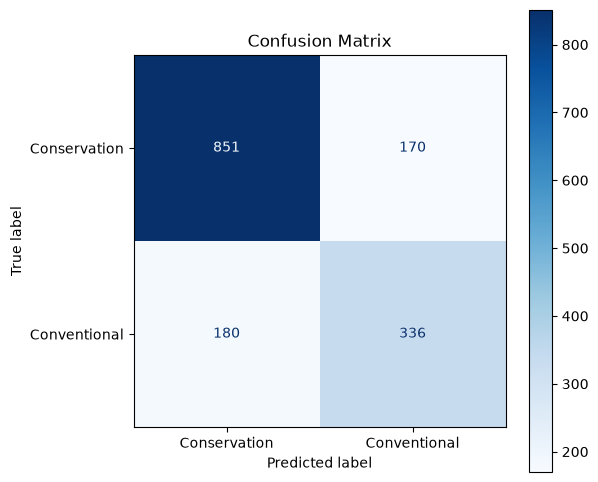


--- Top 5 Important Features ---
1. extra_noise: 0.1308
2. vh__min__mean: 0.0517
3. vv__min__mean: 0.0427
4. vvvh__max__mean: 0.0413
5. vvvh__median__mean: 0.0402
Perm Importance
vh__min__mean       0.008068
vvvh__mean__mean    0.003709
extra_noise         0.001496
NDVI__max__mean     0.001041
vvvh__min__mean     0.000716
dtype: float64
Accuracy --  0.7722836694860117  F1 Score --  0.7717244617720221


In [ ]:
target_to_use = 'baseline'
if('level_0' in mldf.columns): 
    mldf = mldf.drop(columns = ['level_0'])
if('index' in mldf.columns):
    mldf = mldf.drop(columns = ['index'])

mldf_classified = classify_tillage(mldf,target_to_use)
trainables = [col for col in mldf_classified.columns if '__'  in col]
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Baseline classification')
acc , f1 = RFC(mldf_classified ,trainables) 
print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )


++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- Multiclass classification


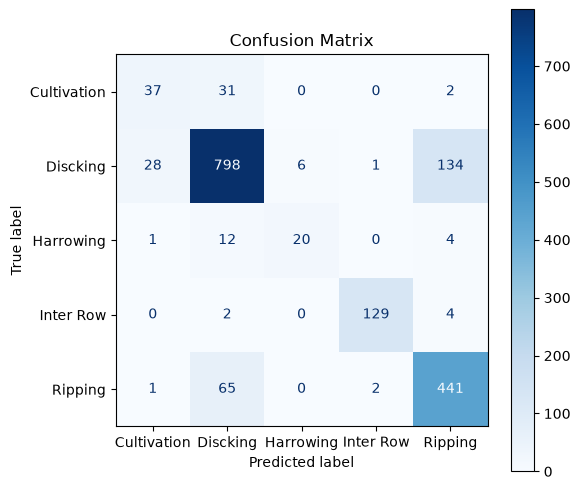


--- Top 5 Important Features ---
1. NDVI__max__mean: 0.0765
2. vh__min__mean: 0.0495
3. vvvh__max__mean: 0.0492
4. vv__max__mean: 0.0484
5. NDVI__median__mean: 0.0457
Perm Importance
vvvh__min__mean    0.015192
NDVI__max__mean    0.010186
NDVI__min__mean    0.001979
vh__min__mean      0.000582
vv__mean__mean     0.000058
dtype: float64
Accuracy --  0.829452852153667  F1 Score --  0.8295843557810407


In [50]:
# ==============================================================================
# 3.-- NOMINAL CLASSES 
# ==============================================================================
target_to_use = 'Nominal' # Options -- baseline (Classifica column), baseline_other(other class included), 
                                            # alex , alex_binary ,
                                            # Nominal, 
                                            # [NOT IMPELEMETD => ]
                                            ## Alex sustainability Score 
                                            #### This is currently approximate. In depth feature extraction with given depth, turnover etc need to be considered. 
if('level_0' in mldf.columns): 
    mldf = mldf.drop(columns = ['level_0'])
if('index' in mldf.columns):
    mldf = mldf.drop(columns = ['index'])
if('Target' in mldf.columns): 
    mldf = mldf.drop(columns = ['Target'])

mldf_classified = classify_tillage(mldf,target_to_use)
trainables = [col for col in mldf_classified.columns if '__'  in col]
mldf_classified = mldf_classified[mldf_classified.Target != 'Plowing']

#print('Plowing fields have a lot of nans for some reason.')

print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Multiclass classification')
acc , f1 = RFC(mldf_classified ,trainables) 
print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- One vs All
Class Cultivation


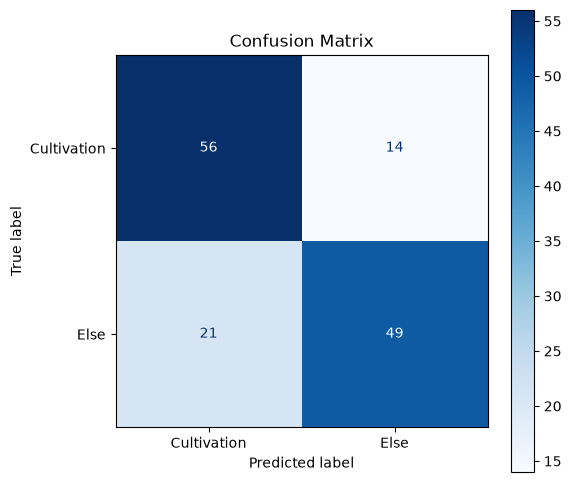


--- Top 5 Important Features ---
1. vh__median__mean: 0.0727
2. vh__min__mean: 0.0658
3. vh__max__mean: 0.0601
4. vh__mean__mean: 0.0480
5. vvvh__max__mean: 0.0470
Perm Importance
NDVI__max__mean      0.024286
vv__max__mean        0.014286
BAI__median__mean    0.014286
STI__min__mean       0.012857
NDVI__mean__mean     0.012143
dtype: float64
Accuracy --  0.75  F1 Score --  0.7493734335839599
Class Discking


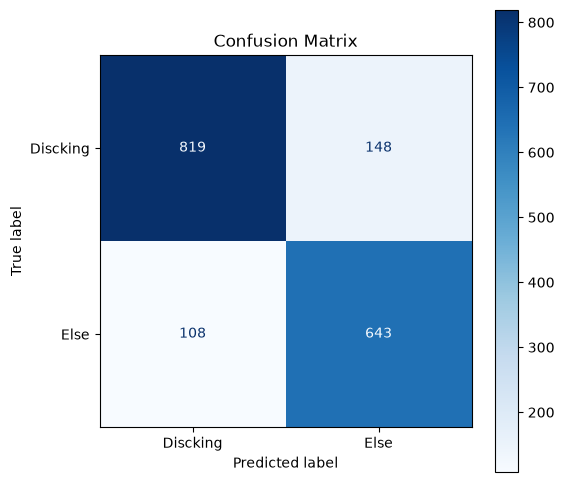


--- Top 5 Important Features ---
1. extra_noise: 0.0820
2. vvvh__min__mean: 0.0604
3. NDVI__max__mean: 0.0568
4. vvvh__max__mean: 0.0497
5. vh__min__mean: 0.0402
Perm Importance
vvvh__min__mean    0.034750
vvvh__max__mean    0.010827
NDVI__max__mean    0.006927
BAI__min__mean     0.003609
vv__max__mean      0.003143
dtype: float64
Accuracy --  0.8509895227008148  F1 Score --  0.8513487134280984
Class Harrowing


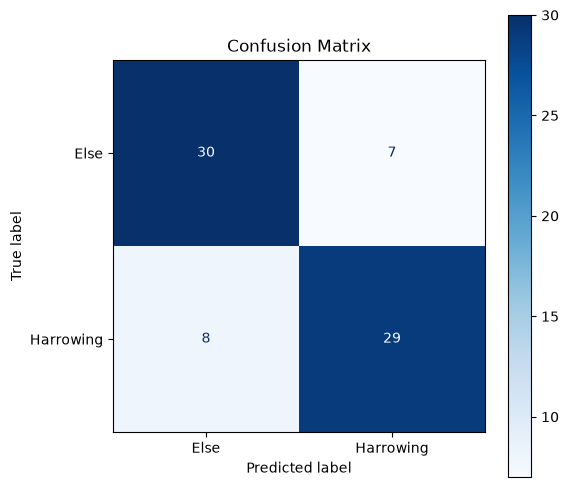


--- Top 5 Important Features ---
1. vvvh__max__mean: 0.0671
2. vvvh__mean__mean: 0.0569
3. vh__min__mean: 0.0564
4. vvvh__median__mean: 0.0528
5. vv__max__mean: 0.0507
Perm Importance
vv__max__mean        0.025676
STI__median__mean    0.021622
vh__mean__mean       0.020270
vv__min__mean        0.020270
vv__mean__mean       0.020270
dtype: float64
Accuracy --  0.7972972972972973  F1 Score --  0.7972602739726027
Class Inter Row


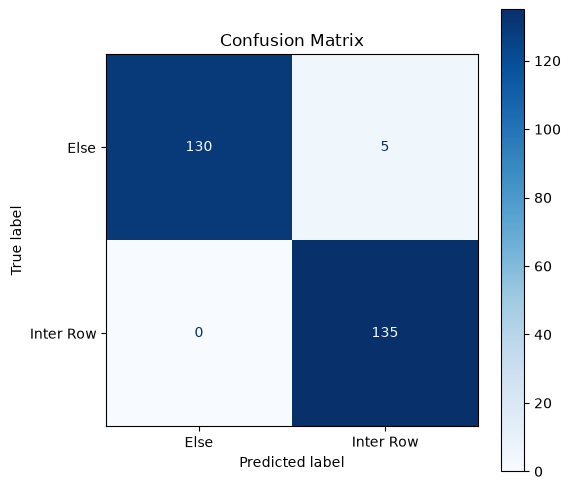


--- Top 5 Important Features ---
1. NDVI__max__mean: 0.1477
2. NDVI__median__mean: 0.0892
3. NDVI__mean__mean: 0.0659
4. vh__median__mean: 0.0631
5. vh__max__mean: 0.0616
Perm Importance
NDVI__max__mean       0.032593
NDVI__median__mean    0.012222
NDVI__mean__mean      0.008148
vvvh__max__mean       0.004444
BAI__max__mean        0.002593
dtype: float64
Accuracy --  0.9814814814814815  F1 Score --  0.9814751286449399
Class Ripping


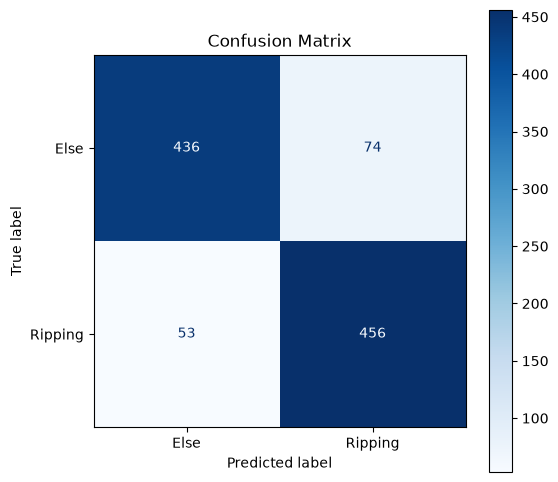


--- Top 5 Important Features ---
1. extra_noise: 0.0658
2. vvvh__min__mean: 0.0616
3. vvvh__max__mean: 0.0513
4. vvvh__median__mean: 0.0467
5. vv__max__mean: 0.0466
Perm Importance
vvvh__min__mean     0.032287
vv__min__mean       0.007458
vvvh__max__mean     0.004907
NDVI__max__mean     0.002846
NDVI__mean__mean    0.002061
dtype: float64
Accuracy --  0.8753680078508341  F1 Score --  0.8753175768262554
Strategy -- Best pair


'This strategy asks the question - Given the data, which two classes are best seperable?'

In [52]:
print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- One vs All') 
ova_df = mldf_classified.copy()
for tillage_class in np.unique(mldf_classified.Target):
    print('Class', tillage_class)
    if(len(mldf_classified[mldf_classified.Target == tillage_class]) <6):
        print('Skipping since low count')
        continue
    ova_df = balance_one_vs_all_df(mldf_classified, target_col="Target", target_class=tillage_class)
    acc , f1 = RFC(ova_df ,trainables) 
    print( 'Accuracy -- ',acc , " F1 Score -- ",f1 )

print('Strategy -- Best pair')
'''This strategy asks the question - Given the data, which two classes are best seperable?'''

In [ ]:
acc

0.26666666666666666

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- Ordinal Regression -- Alex Sustainability

--- Top 5 Important Features ---
1. NDVI__max__mean: 0.2895
2. vvvh__max__mean: 0.0528
3. BAI__max__mean: 0.0508
4. vvvh__min__mean: 0.0471
5. vv__max__mean: 0.0390


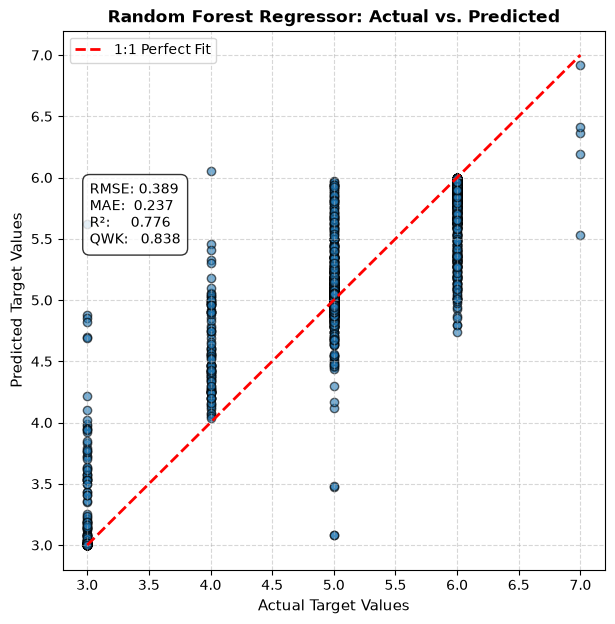

In [53]:
# ==============================================================================
# 3. ML & VISUALIZATION -- ORDINAL CLASSES 
# ==============================================================================
target_to_use = 'alex'
if('level_0' in mldf.columns): 
    mldf = mldf.drop(columns = ['level_0'])
if('index' in mldf.columns):
    mldf = mldf.drop(columns = ['index'])

mldf_classified = classify_tillage(mldf,target_to_use)

print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Ordinal Regression -- Alex Sustainability')
rmse, mae, r2, qwk = RFR(mldf_classified,trainables)

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Strategy -- Ordinal Regression -- Alex Sustainability

--- Top 5 Important Features ---
1. NDVI__max__mean: 0.0996
2. extra_noise: 0.0746
3. vvvh__min__mean: 0.0705
4. vv__min__mean: 0.0555
5. vvvh__max__mean: 0.0547


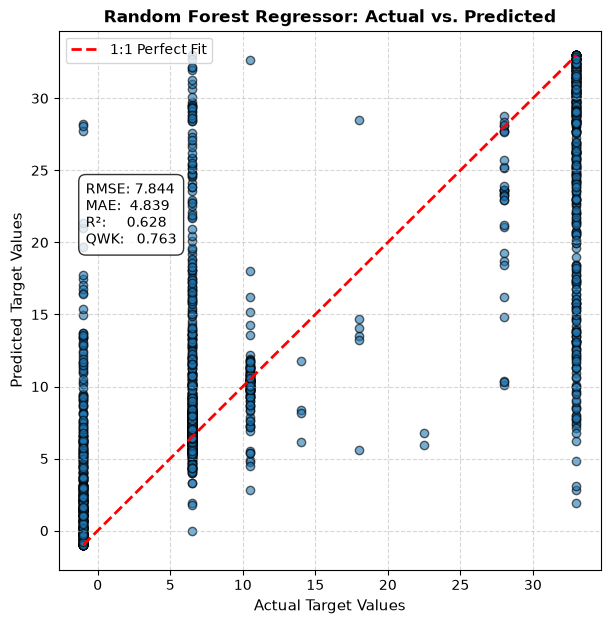

In [56]:
target_to_use = 'Extracted_Depth'
if('level_0' in mldf.columns): 
    mldf = mldf.drop(columns = ['level_0'])
if('index' in mldf.columns):
    mldf = mldf.drop(columns = ['index'])

mldf_classified = classify_tillage(mldf,target_to_use)

print('++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++')
print('Strategy -- Ordinal Regression -- Alex Sustainability')
rmse, mae, r2, qwk = RFR(mldf_classified,trainables)

In [ ]:
1/0

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex_binary'): 
    #minval = min(analysis_df.Target)
    val = analysis_df.Target.mean()
    analysis_df["binary_target"] =  (analysis_df['Target'] > val).astype(int)
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1_unidirectional, best_acc_unidirectional, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    
    if(target_to_use in ['baseline', 'alex_binary']):
        y_pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
    elif(target_to_use == 'alex'): 

        f1 = f1_score(y_true, y_pred, zero_division=0, average = 'micro') 
    else:
        NotImplementedError
    acc = accuracy_score(y_true, y_pred) 
    f1 = f1 if f1>0.5 else 1-f1 
    acc = acc if acc>0.5 else 1-acc
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc_unidirectional or (f1 > best_f1_unidirectional and acc == best_acc_unidirectional):
        best_f1_unidirectional, best_acc_unidirectional, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score (Unidirectional):     {best_f1_unidirectional:.4f}")
print(f"Overall Accuracy (Unidirectional):       {best_acc_unidirectional:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

label0 , label1 = np.unique(analysis_df['Target'].astype(str))
ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label=label0)
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label=label1)
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



NotImplementedError: 

In [ ]:
1/0

In [ ]:
# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION -- COPY
# ==============================================================================

if(target_to_use == 'baseline'):
    # Encode target: Conventional = 0, Conservation = 1
    analysis_df["binary_target"] = (analysis_df["Target"].str.lower() == "conservation").astype(int)
elif(target_to_use == 'alex'): 
    minval = min(analysis_df.Target)
    analysis_df["binary_target"] =  analysis_df['binary_target'] - minval  
else: 
    raise NotImplementedError 
y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1, best_acc, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    y_pred = (scores >= t).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc or (f1 > best_f1 and acc == best_acc):
        best_f1, best_acc, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score:     {best_f1:.4f}")
print(f"Overall Accuracy:       {best_acc:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label="Conventional")
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label="Conservation")
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()